In [4]:
import pandas as pd

# Load the datasets
vix_df = pd.read_csv('C:/Users/guosh/OneDrive/Desktop/mfams/VIXCLS_volatility.csv')
fx_df = pd.read_csv('C:/Users/guosh/OneDrive/Desktop/mfams/FXdataDaily_2005_to_2026_Dev_and_underdeve/daily.csv')

# Display the first few rows of each
print("VIX Volatility Data (first 5 rows):")
print(vix_df.head())

print("\nFX Daily Data (first 5 rows):")
print(fx_df.head())

VIX Volatility Data (first 5 rows):
  observation_date  VIXCLS
0       2005-01-03   14.08
1       2005-01-04   13.98
2       2005-01-05   14.09
3       2005-01-06   13.58
4       2005-01-07   13.49

FX Daily Data (first 5 rows):
  observation_date  DEXBZUS  DEXCAUS  DEXCHUS  DEXDNUS  DEXHKUS  DEXINUS  \
0       2005-01-03   2.6695   1.2108   8.2765   5.5161   7.7775    43.35   
1       2005-01-04   2.7020   1.2248   8.2765   5.5927   7.7851    43.47   
2       2005-01-05   2.6970   1.2236   8.2765   5.5959   7.7881    43.60   
3       2005-01-06   2.7190   1.2371   8.2765   5.6417   7.7935    43.75   
4       2005-01-07   2.7095   1.2333   8.2765   5.6951   7.7920    43.63   

   DEXJPUS  DEXKOUS  DEXMAUS  ...  DEXUSEU  DEXUSNZ  DEXUSUK  DEXVZUS  \
0   102.83   1038.0      3.8  ...   1.3476   0.7148   1.9058   1.9152   
1   104.27   1038.0      3.8  ...   1.3295   0.7069   1.8834   1.9152   
2   103.95   1046.3      3.8  ...   1.3292   0.7030   1.8875   1.9152   
3   104.87   1058.0   

In [5]:
# Convert VIXCLS column to numeric, handling missing or non-numeric values (coercing them to NaN)
vix_df['VIXCLS'] = pd.to_numeric(vix_df['VIXCLS'], errors='coerce')

# Filter the rows based on the threshold of 30
High_volatility = vix_df[vix_df['VIXCLS'] > 30].copy()
Medium_volatility = vix_df[(vix_df['VIXCLS'] <= 30) & (vix_df['VIXCLS'] > 15)].copy()
Low_volatility = vix_df[vix_df['VIXCLS'] <= 15].copy()

# Display the sizes and preview of each dataset
print(f"High Volatility shape: {High_volatility.shape}")
print(f"Medium Volatility shape: {Medium_volatility.shape}")
print(f"Low Volatility shape: {Low_volatility.shape}")

print("\nHigh Volatility Preview:")
display(High_volatility.head())

print("\nMedium Volatility Preview:")
display(Medium_volatility.head())

print("\nLow Volatility Preview:")
display(Low_volatility.head())

High Volatility shape: (450, 2)
Medium Volatility shape: (3045, 2)
Low Volatility shape: (2019, 2)

High Volatility Preview:


,observation_date,VIXCLS
682,2007-08-15,30.67
683,2007-08-16,30.83
745,2007-11-12,31.09
796,2008-01-22,31.01
834,2008-03-14,31.16



Medium Volatility Preview:


,observation_date,VIXCLS
74,2005-04-15,17.74
75,2005-04-18,16.56
77,2005-04-20,16.92
79,2005-04-22,15.38
83,2005-04-28,16.86



Low Volatility Preview:


,observation_date,VIXCLS
0,2005-01-03,14.08
1,2005-01-04,13.98
2,2005-01-05,14.09
3,2005-01-06,13.58
4,2005-01-07,13.49


In [6]:
import pandas as pd
import numpy as np

# Create a copy of the FX dataframe
fx_calc = fx_df.copy()

# Set observation_date as the index
if 'observation_date' in fx_calc.columns:
    fx_calc.set_index('observation_date', inplace=True)

# Ensure all currency exchange rate columns are numeric
for col in fx_calc.columns:
    fx_calc[col] = pd.to_numeric(fx_calc[col], errors='coerce')

# Calculate daily percentage returns
fx_returns = fx_calc.pct_change()

# Calculate the lag-1 autocorrelation for each currency pair return series
autocorrelations = {}
for col in fx_returns.columns:
    # Drop NaNs to calculate clean autocorrelation
    clean_returns = fx_returns[col].dropna()
    if len(clean_returns) > 1:
        autocorrelations[col] = clean_returns.autocorr(lag=1)
    else:
        autocorrelations[col] = np.nan

# Convert to a DataFrame for neat display
autocorr_df = pd.DataFrame.from_dict(autocorrelations, orient='index', columns=['Lag_1_Autocorrelation'])
autocorr_df.index.name = 'FX_Pair'
autocorr_df = autocorr_df.sort_values(by='Lag_1_Autocorrelation', ascending=False)

display(autocorr_df)

,Lag_1_Autocorrelation
FX_Pair,
DTWEXO,0.061244
DEXSZUS,0.042301
DTWEXEMEGS,0.039950
DEXSLUS,0.034746
DTWEXB,0.031868
DTWEXBGS,0.029748
DEXUSUK,0.028119
DEXTHUS,0.026458
DEXMAUS,0.023785


In [7]:
# Identify the dates for high and low volatility periods
high_vol_dates = High_volatility['observation_date'].values
low_vol_dates = Low_volatility['observation_date'].values

# Filter the FX daily returns (fx_returns) for these specific periods
# Note: fx_returns has 'observation_date' as its index
high_vol_returns = fx_returns.loc[fx_returns.index.isin(high_vol_dates)]
low_vol_returns = fx_returns.loc[fx_returns.index.isin(low_vol_dates)]

# Calculate lag-1 autocorrelation for both regimes
comparison_data = {}
for col in fx_returns.columns:
    # High Volatility Autocorrelation
    high_clean = high_vol_returns[col].dropna()
    high_corr = high_clean.autocorr(lag=1) if len(high_clean) > 1 else np.nan

    # Low Volatility Autocorrelation
    low_clean = low_vol_returns[col].dropna()
    low_corr = low_clean.autocorr(lag=1) if len(low_clean) > 1 else np.nan

    comparison_data[col] = {
        'High_Vol_Autocorr': high_corr,
        'Low_Vol_Autocorr': low_corr,
        'Difference_(High_minus_Low)': high_corr - low_corr if not (np.isnan(high_corr) or np.isnan(low_corr)) else np.nan
    }

# Convert to a DataFrame for analysis
comparison_df = pd.DataFrame.from_dict(comparison_data, orient='index')
comparison_df.index.name = 'FX_Pair'
comparison_df = comparison_df.sort_values(by='Difference_(High_minus_Low)', ascending=False)

display(comparison_df)

,High_Vol_Autocorr,Low_Vol_Autocorr,Difference_(High_minus_Low)
FX_Pair,,,
DEXINUS,0.083986,-0.050328,0.134315
DEXTHUS,0.129762,0.019114,0.110648
DEXSZUS,0.070186,-0.009213,0.079399
DEXUSEU,0.053638,-0.013894,0.067531
DEXDNUS,0.047298,-0.012565,0.059863
DEXSFUS,0.072247,0.012731,0.059516
DEXVZUS,-0.002388,-0.043755,0.041367
DEXUSUK,0.040055,0.003236,0.036819
DEXJPUS,0.070795,0.046423,0.024372


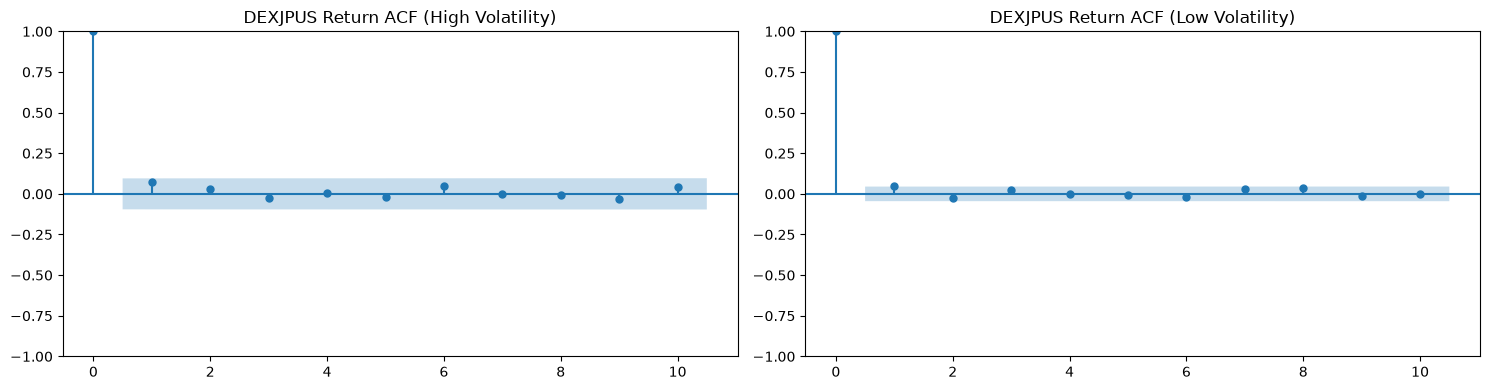

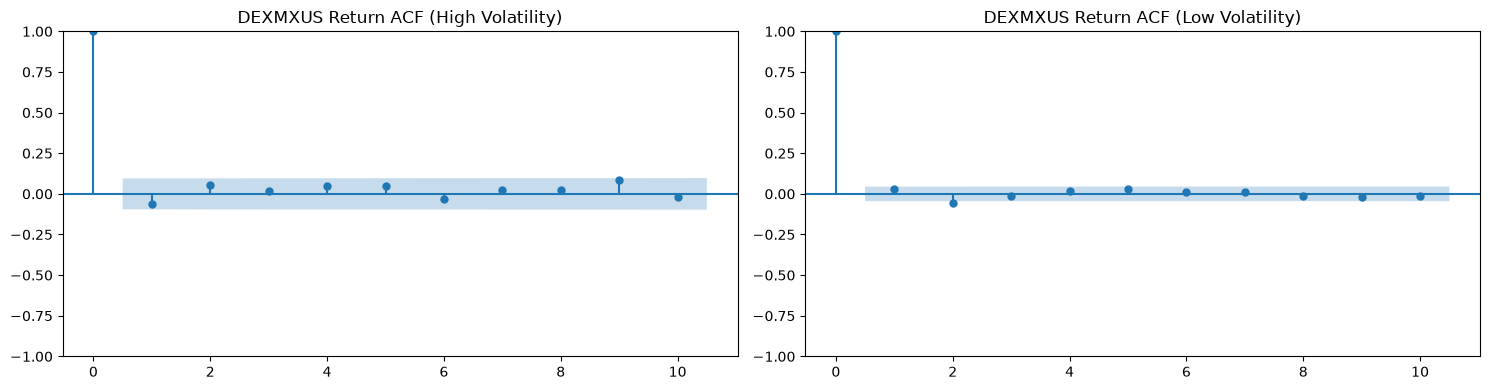

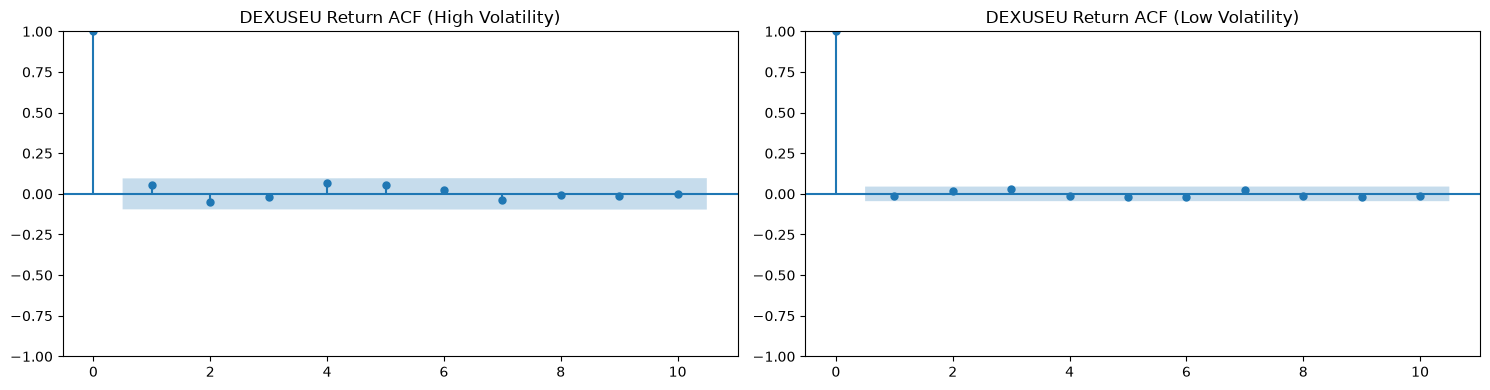

In [8]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

# Select a few representative FX pairs to plot for comparison
# (e.g., DEXJPUS for safe-haven/momentum shift, DEXMXUS for emerging market/reversion shift)
selected_pairs = ['DEXJPUS', 'DEXMXUS', 'DEXUSEU']

for pair in selected_pairs:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))

    # Get clean return series for both regimes
    high_series = high_vol_returns[pair].dropna()
    low_series = low_vol_returns[pair].dropna()

    # Plot ACF for High Volatility
    if len(high_series) > 0:
        plot_acf(high_series, ax=axes[0], lags=10, title=f'{pair} Return ACF (High Volatility)')
    else:
        axes[0].set_title(f'{pair} (No Data for High Vol)')

    # Plot ACF for Low Volatility
    if len(low_series) > 0:
        plot_acf(low_series, ax=axes[1], lags=10, title=f'{pair} Return ACF (Low Volatility)')
    else:
        axes[1].set_title(f'{pair} (No Data for Low Vol)')

    plt.tight_layout()
    plt.show()

In [9]:
# Ensure we have clean daily returns calculated
fx_calc = fx_df.copy()
if 'observation_date' in fx_calc.columns:
    fx_calc.set_index('observation_date', inplace=True)

for col in fx_calc.columns:
    fx_calc[col] = pd.to_numeric(fx_calc[col], errors='coerce')

# Calculate daily percentage returns (ignoring deprecation warning behavior)
fx_returns = fx_calc.pct_change(fill_method=None)

# Helper function to compute rolling autocorrelation
def rolling_autocorr(series, window=30, lag=1):
    return series.rolling(window=window).apply(lambda x: x.autocorr(lag=lag) if len(x.dropna()) > lag else np.nan)

# Calculate rolling autocorrelations for all columns in fx_returns
rolling_autocorr_df = pd.DataFrame(index=fx_returns.index)

for col in fx_returns.columns:
    if fx_returns[col].notna().sum() > 30:
        rolling_autocorr_df[col] = rolling_autocorr(fx_returns[col], window=30, lag=1)

print("Rolling Lag-1 Autocorrelations Calculated Successfully. Preview:")
display(rolling_autocorr_df)

Rolling Lag-1 Autocorrelations Calculated Successfully. Preview:


,DEXBZUS,DEXCAUS,DEXCHUS,DEXDNUS,DEXHKUS,DEXINUS,DEXJPUS,DEXKOUS,DEXMAUS,DEXMXUS,...,DEXUSEU,DEXUSNZ,DEXUSUK,DEXVZUS,DTWEXAFEGS,DTWEXB,DTWEXBGS,DTWEXEMEGS,DTWEXM,DTWEXO
observation_date,,,,,,,,,,,,,,,,,,,,,
2005-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2005-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-10-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


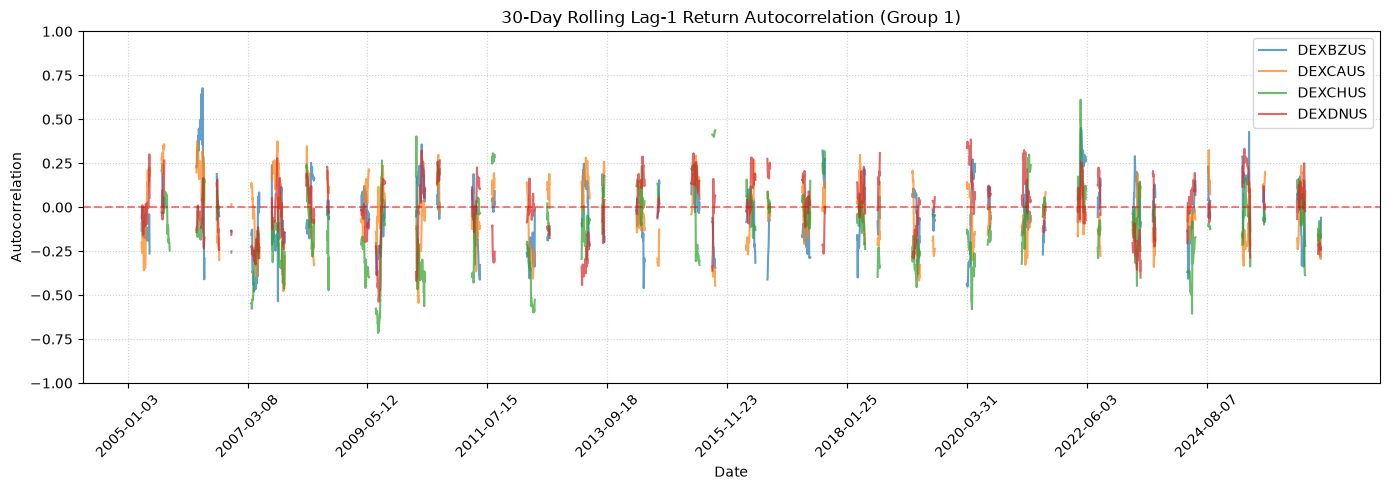

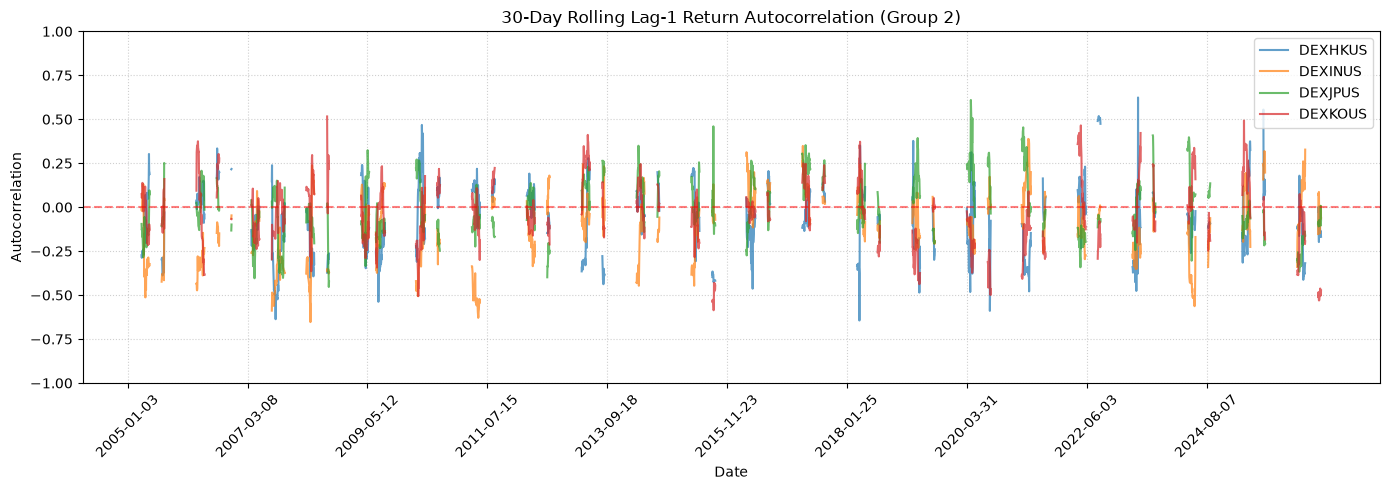

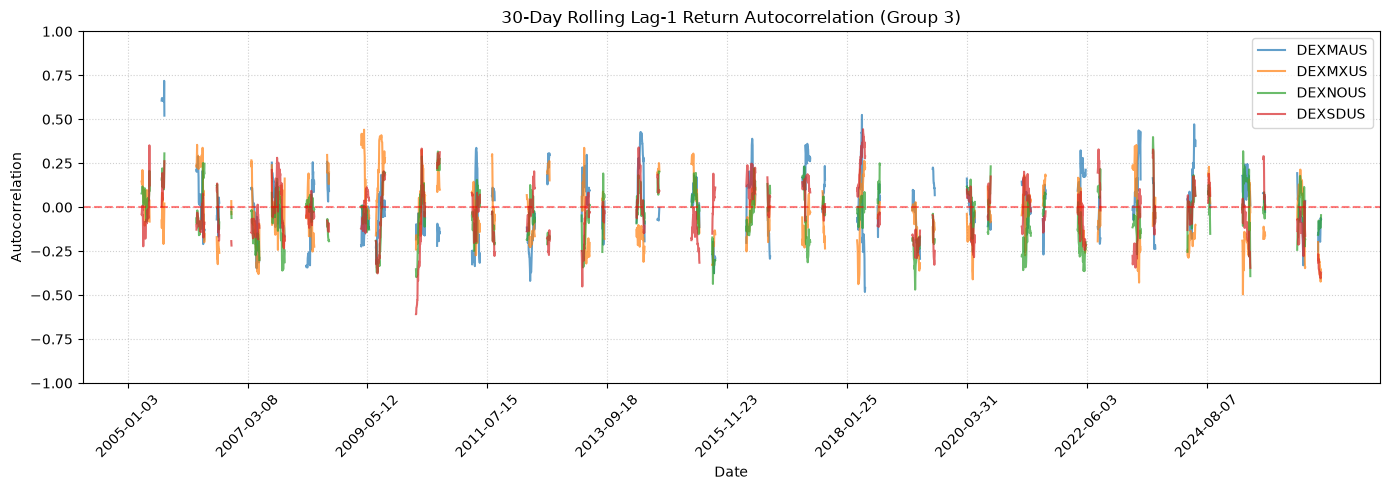

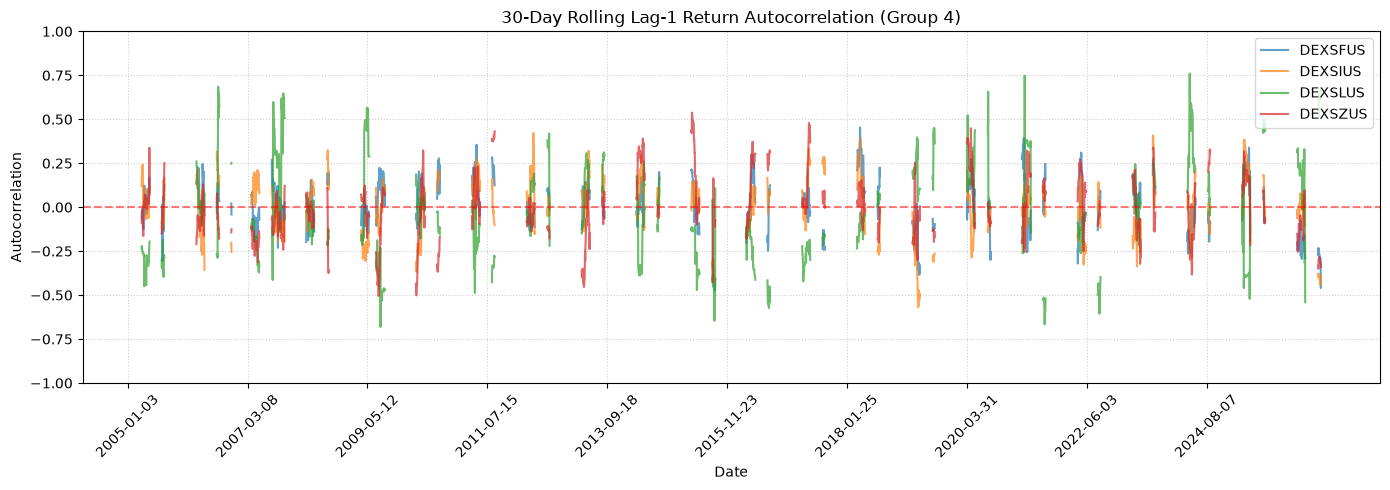

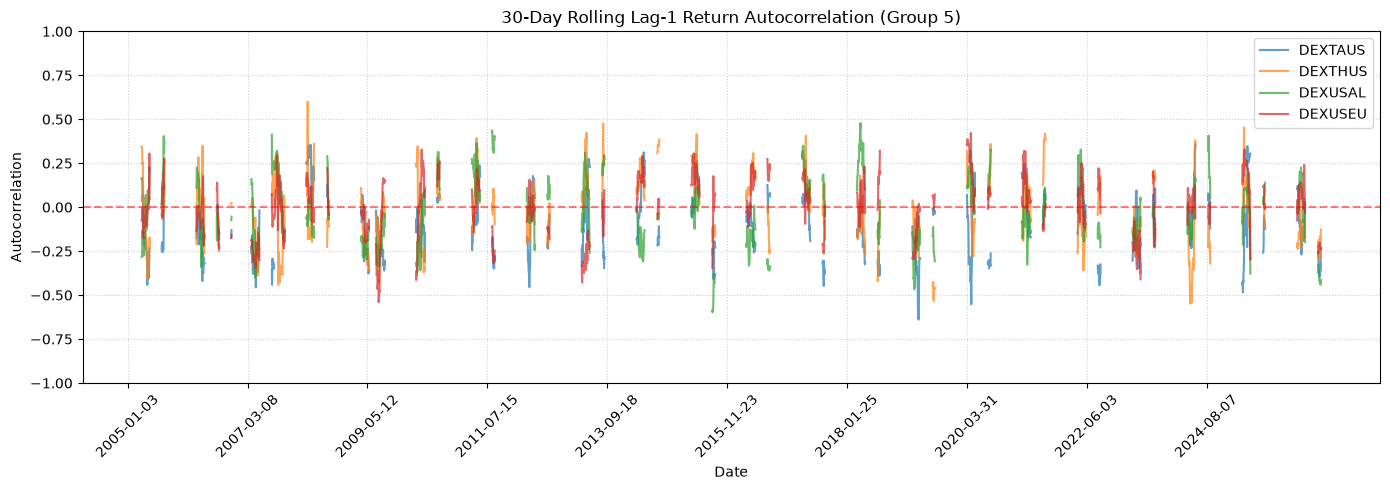

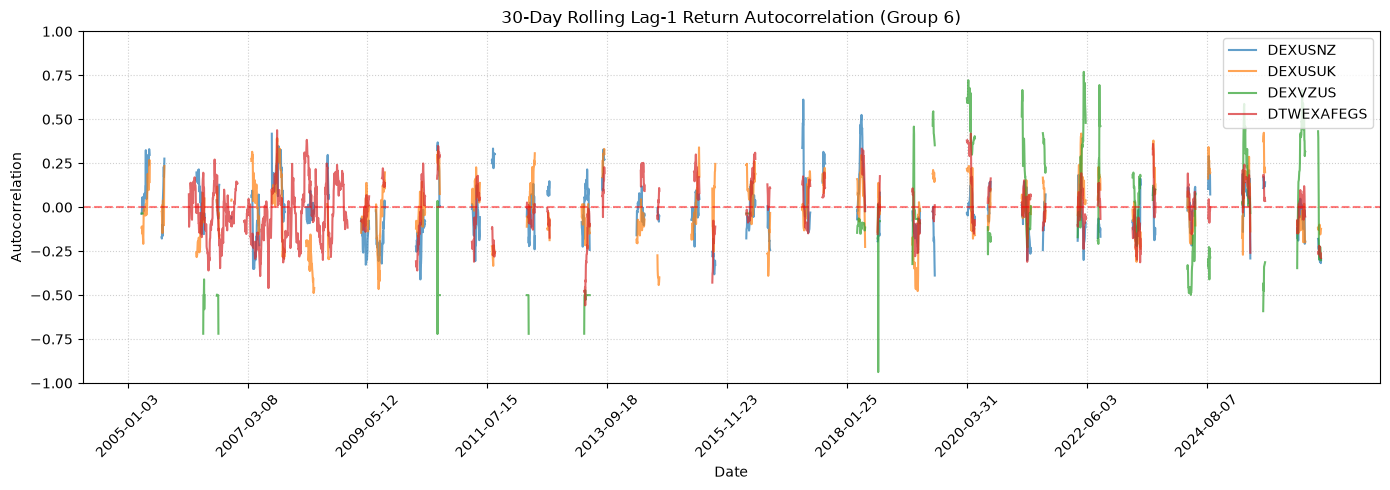

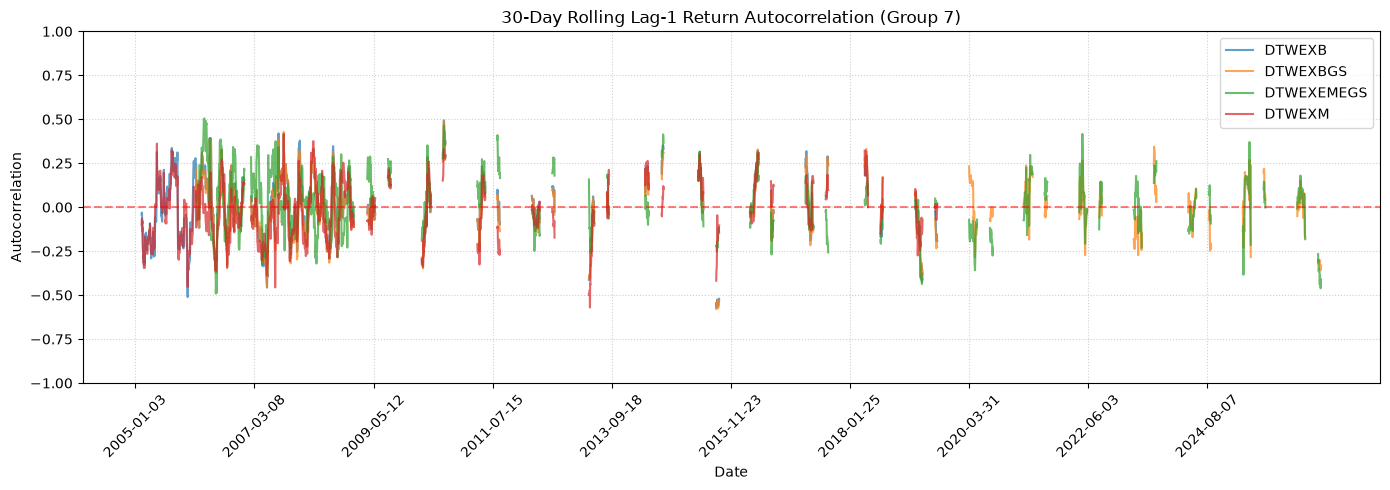

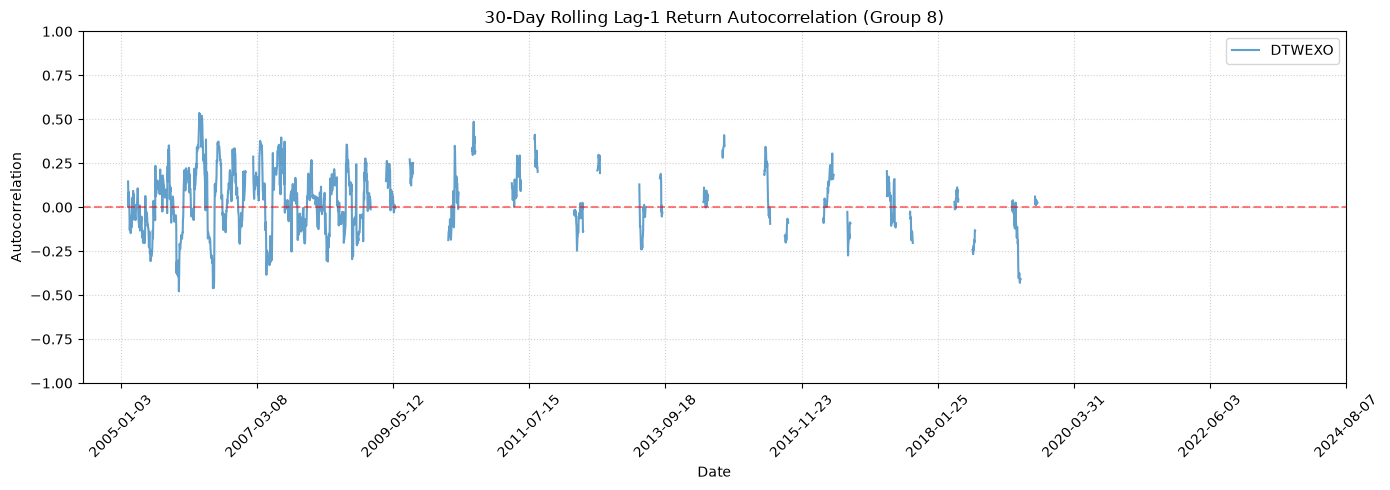

In [10]:
# Identify valid columns to plot
columns_to_plot = [col for col in rolling_autocorr_df.columns if not rolling_autocorr_df[col].isnull().all()]
batch_size = 4
num_batches = int(np.ceil(len(columns_to_plot) / batch_size))

# Plot rolling autocorrelations in small batches
for b in range(num_batches):
    batch_cols = columns_to_plot[b * batch_size : (b + 1) * batch_size]
    plt.figure(figsize=(14, 5))
    for col in batch_cols:
        plt.plot(rolling_autocorr_df.index, rolling_autocorr_df[col], label=col, alpha=0.7, linewidth=1.5)

    plt.title(f'30-Day Rolling Lag-1 Return Autocorrelation (Group {b+1})')
    plt.xlabel('Date')
    plt.ylabel('Autocorrelation')
    plt.axhline(0, color='red', linestyle='--', alpha=0.5)
    plt.ylim(-1, 1)
    plt.legend(loc='upper right')
    plt.grid(True, linestyle=':', alpha=0.6)

    # Display dates cleanly
    step = max(1, len(rolling_autocorr_df) // 10)
    plt.xticks(rolling_autocorr_df.index[::step], rotation=45)
    plt.tight_layout()
    plt.show()

,High Vol Regime Mean Absolute Error,Med Vol Regime Mean Absolute Error,Low Vol Regime Mean Absolute Error,High Vol Regime RMSE,Low Vol Regime RMSE
DEXJPUS,0.951115,0.397046,0.339640,2.244042,0.694437
DEXMXUS,2.247616,0.459051,0.419924,5.028241,1.448068
DEXUSEU,0.894160,0.282975,0.239240,1.788674,0.429195


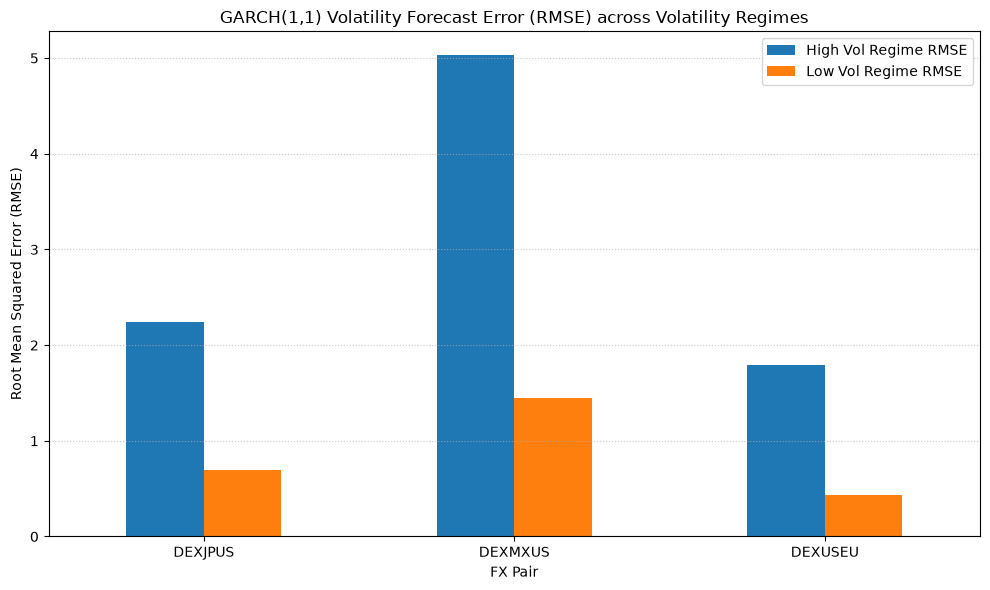

In [11]:
from arch import arch_model

# Define the representative currency pairs we want to analyze
selected_pairs = ['DEXJPUS', 'DEXMXUS', 'DEXUSEU']

# We will store forecast errors for each pair under different VIX regimes
comparison_results = {}

# Identify regime dates based on our VIX-based dataframes
high_vol_dates = set(High_volatility['observation_date'].values)
med_vol_dates = set(Medium_volatility['observation_date'].values)
low_vol_dates = set(Low_volatility['observation_date'].values)

for pair in selected_pairs:
    # Clean and scale returns to percentage
    returns_series = fx_returns[pair].dropna() * 100

    # Fit GARCH(1,1) model
    model = arch_model(returns_series, vol='Garch', p=1, q=1, dist='normal')
    fit_res = model.fit(disp='off')

    # Volatility forecast error:
    # Realized Volatility Proxy (Squared returns) minus GARCH predicted Conditional Variance
    realized_var = returns_series ** 2
    garch_var = fit_res.conditional_volatility ** 2
    forecast_error = (realized_var - garch_var)

    # Align forecast errors back to their original observation dates
    fe_df = pd.DataFrame({'Forecast_Error': forecast_error}, index=returns_series.index)

    # Segment the forecast errors into the VIX-based regimes
    high_errors = fe_df.loc[fe_df.index.isin(high_vol_dates), 'Forecast_Error'].dropna()
    med_errors = fe_df.loc[fe_df.index.isin(med_vol_dates), 'Forecast_Error'].dropna()
    low_errors = fe_df.loc[fe_df.index.isin(low_vol_dates), 'Forecast_Error'].dropna()

    comparison_results[pair] = {
        'High Vol Regime Mean Absolute Error': np.abs(high_errors).mean(),
        'Med Vol Regime Mean Absolute Error': np.abs(med_errors).mean(),
        'Low Vol Regime Mean Absolute Error': np.abs(low_errors).mean(),
        'High Vol Regime RMSE': np.sqrt((high_errors ** 2).mean()),
        'Low Vol Regime RMSE': np.sqrt((low_errors ** 2).mean())
    }

    # Convert results to DataFrame for display
comparison_errors_df = pd.DataFrame(comparison_results).T
display(comparison_errors_df)

# Plot the comparison of Root Mean Squared Volatility Forecast Errors
comparison_errors_df[['High Vol Regime RMSE', 'Low Vol Regime RMSE']].plot(kind='bar', figsize=(10, 6))
plt.title('GARCH(1,1) Volatility Forecast Error (RMSE) across Volatility Regimes')
plt.ylabel('Root Mean Squared Error (RMSE)')
plt.xlabel('FX Pair')
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Refitted through forecast 500 of 4,954 (2008-12-22).
Refitted through forecast 1,000 of 4,954 (2010-12-17).
Refitted through forecast 1,500 of 4,954 (2012-12-14).
Refitted through forecast 2,000 of 4,954 (2014-12-12).
Refitted through forecast 2,500 of 4,954 (2016-12-12).
Refitted through forecast 3,000 of 4,954 (2018-12-12).
Refitted through forecast 3,500 of 4,954 (2020-12-15).
Refitted through forecast 4,000 of 4,954 (2022-12-16).
Refitted through forecast 4,500 of 4,954 (2024-12-17).


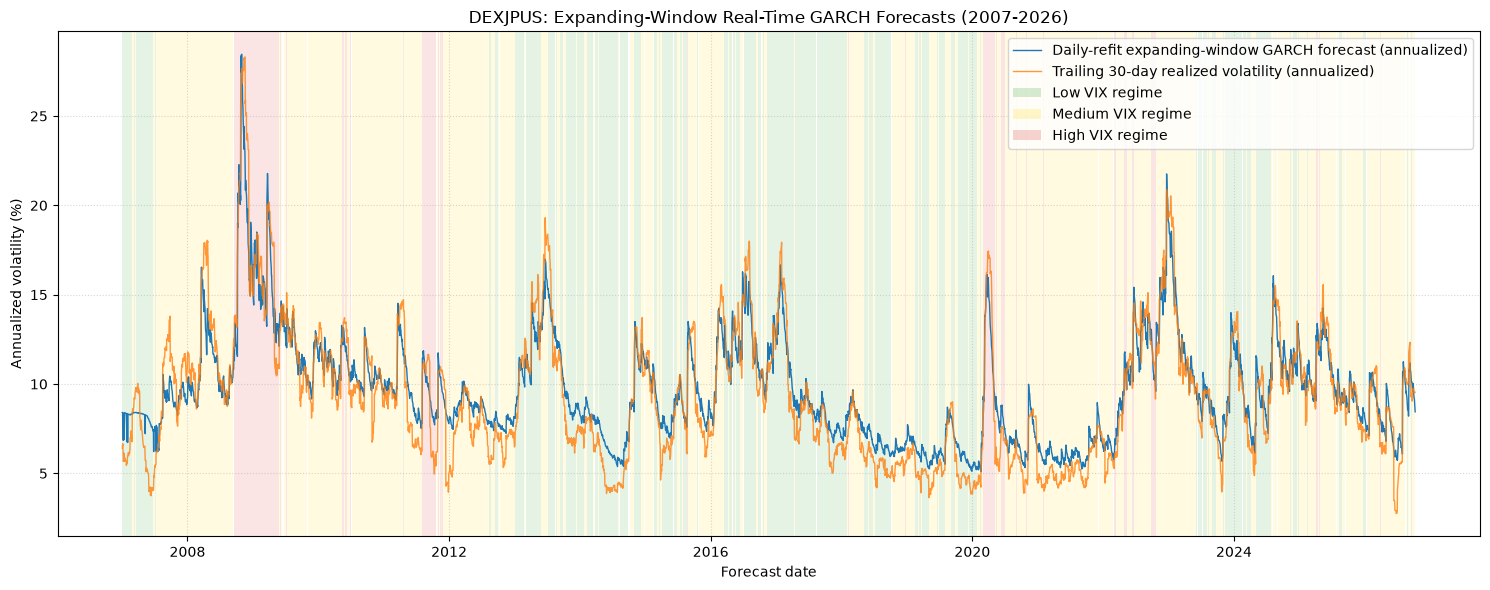

Initial fit period: 2005-01-04 to 2006-12-29
Forecast period: 2007-01-02 to 2026-10-09
Daily refits/forecasts: 4,954


In [12]:
# Expanding-window real-time GARCH(1,1) forecasts for DEXJPUS.
# Estimate on 2005-2006, then refit each day using only returns available
# before that day's forecast; add the observed return after forecasting.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from arch import arch_model

expanding_fx = fx_df[['observation_date', 'DEXJPUS']].copy()
expanding_fx['observation_date'] = pd.to_datetime(expanding_fx['observation_date'], errors='coerce')
expanding_fx['DEXJPUS'] = pd.to_numeric(expanding_fx['DEXJPUS'], errors='coerce')
expanding_fx = expanding_fx.dropna().set_index('observation_date').sort_index()
expanding_returns = expanding_fx['DEXJPUS'].pct_change(fill_method=None).dropna() * 100

initial_returns = expanding_returns.loc['2005-01-01':'2006-12-31']
forecast_returns = expanding_returns.loc['2007-01-01':'2026-12-31']
if initial_returns.empty or forecast_returns.empty:
    raise ValueError('DEXJPUS data must include returns in both 2005-2006 and 2007-2026.')

expanding_history = initial_returns.copy()
expanding_forecast_variances = pd.Series(
    index=forecast_returns.index,
    dtype=float,
    name='One-day-ahead GARCH forecast variance'
)

for step, (forecast_date, observed_return) in enumerate(forecast_returns.items(), start=1):
    expanding_model = arch_model(
        expanding_history,
        mean='Constant',
        vol='Garch',
        p=1,
        q=1,
        dist='normal'
    )
    expanding_fit = expanding_model.fit(disp='off')
    forecast_variance = expanding_fit.forecast(horizon=1, reindex=False).variance.iloc[-1, 0]
    expanding_forecast_variances.loc[forecast_date] = forecast_variance

    # Include today's observed return only after its forecast has been recorded.
    expanding_history.loc[forecast_date] = observed_return

    if step % 500 == 0:
        print(f'Refitted through forecast {step:,} of {len(forecast_returns):,} ({forecast_date.date()}).')

expanding_forecast_volatility = np.sqrt(expanding_forecast_variances) * np.sqrt(252)
expanding_realized_volatility = (
    expanding_returns.rolling(window=30, min_periods=30).std() * np.sqrt(252)
).reindex(forecast_returns.index)

expanding_vix = vix_df[['observation_date', 'VIXCLS']].copy()
expanding_vix['observation_date'] = pd.to_datetime(expanding_vix['observation_date'], errors='coerce')
expanding_vix['VIXCLS'] = pd.to_numeric(expanding_vix['VIXCLS'], errors='coerce')
expanding_vix = expanding_vix.dropna().set_index('observation_date')['VIXCLS'].sort_index()
expanding_vix = expanding_vix.reindex(forecast_returns.index, method='ffill')
if expanding_vix.notna().sum() == 0:
    raise ValueError('No VIX observations overlap the GARCH forecast period.')

expanding_vix_regime = pd.Series(
    np.select([expanding_vix > 30, expanding_vix > 15], ['High', 'Medium'], default='Low'),
    index=expanding_vix.index,
).where(expanding_vix.notna())
expanding_regime_colors = {'Low': 'tab:green', 'Medium': 'gold', 'High': 'tab:red'}
expanding_regime_groups = expanding_vix_regime.ne(expanding_vix_regime.shift()).cumsum()


fig, ax = plt.subplots(figsize=(15, 6))
for _, regime_dates in expanding_vix_regime.groupby(expanding_regime_groups):
    regime = regime_dates.iloc[0]
    if pd.notna(regime):
        ax.axvspan(
            regime_dates.index[0],
            regime_dates.index[-1] + pd.Timedelta(days=1),
            color=expanding_regime_colors[regime],
            alpha=0.12,
            linewidth=0,
            zorder=0,
        )
ax.plot(
    expanding_forecast_volatility.index,
    expanding_forecast_volatility,
    color='tab:blue',
    linewidth=1,
    label='Daily-refit expanding-window GARCH forecast (annualized)'
)
ax.plot(
    expanding_realized_volatility.index,
    expanding_realized_volatility,
    color='tab:orange',
    linewidth=1,
    alpha=0.8,
    label='Trailing 30-day realized volatility (annualized)'
)
ax.set_title('DEXJPUS: Expanding-Window Real-Time GARCH Forecasts (2007-2026)')
ax.set_xlabel('Forecast date')
ax.set_ylabel('Annualized volatility (%)')
ax.grid(True, linestyle=':', alpha=0.5)
line_handles, line_labels = ax.get_legend_handles_labels()
regime_handles = [
    Patch(facecolor=expanding_regime_colors[name], alpha=0.2, label=f'{name} VIX regime')
    for name in ['Low', 'Medium', 'High']
]
ax.legend(handles=line_handles + regime_handles,
          labels=line_labels + [handle.get_label() for handle in regime_handles])
fig.tight_layout()
plt.show()

print(f'Initial fit period: {initial_returns.index.min().date()} to {initial_returns.index.max().date()}')
print(f'Forecast period: {forecast_returns.index.min().date()} to {forecast_returns.index.max().date()}')
print(f'Daily refits/forecasts: {expanding_forecast_volatility.notna().sum():,}')

In [13]:
# 1. Load the newly created daily S&P 500 dataset and daily currency dataset
sp500_daily = pd.read_csv('C:/Users/guosh/OneDrive/Desktop/mfams/sp500_price_2005_to_now.csv')
daily_df = pd.read_csv('C:/Users/guosh/OneDrive/Desktop/mfams/FXdataDaily_2005_to_2026_Dev_and_underdeve/daily.csv')


# Convert Date columns to datetime format
sp500_daily['Date'] = pd.to_datetime(sp500_daily['Date'])
daily_df['Date'] = pd.to_datetime(daily_df['observation_date'])

# Set Date as index
sp500_daily.set_index('Date', inplace=True)
daily_df.set_index('Date', inplace=True)

# Clean and convert the JPY/USD column ('DEXJPUS') to numeric
daily_df['DEXJPUS'] = pd.to_numeric(daily_df['DEXJPUS'], errors='coerce')
daily_df.dropna(subset=['DEXJPUS'], inplace=True)

# 2. Create columns for percentage returns each day
sp500_daily['sp500_pct_return'] = sp500_daily['Value'].pct_change()
daily_df['jpy_pct_return'] = daily_df['DEXJPUS'].pct_change()

# 3. Merge datasets using Date as index
merged_df = pd.merge(
    sp500_daily[['Value', 'sp500_pct_return']],
    daily_df[['DEXJPUS', 'jpy_pct_return']],
    left_index=True,
    right_index=True,
    how='inner'
).sort_index()

# Rename columns for clarity
merged_df.rename(columns={'Value': 'sp500_price', 'DEXJPUS': 'jpy_price'}, inplace=True)

# Drop rows with NaN values in returns
merged_df.dropna(subset=['sp500_pct_return', 'jpy_pct_return'], inplace=True)

display(merged_df.head())

,sp500_price,sp500_pct_return,jpy_price,jpy_pct_return
Date,,,,
2005-01-04,1188.050049,-0.011671,104.27,0.014004
2005-01-05,1183.739990,-0.003628,103.95,-0.003069
2005-01-06,1187.890015,0.003506,104.87,0.008850
2005-01-07,1186.189941,-0.001431,104.93,0.000572
2005-01-10,1190.250000,0.003423,104.32,-0.005813


Beta measures the volatility (or systematic risk) of JPY/USD returns compared to the S&P 500 returns. Formula:  β=Covariance(Rjpy,Rsp500)Variance(Rsp500)  We will compute this over a rolling window of 252 trading days.

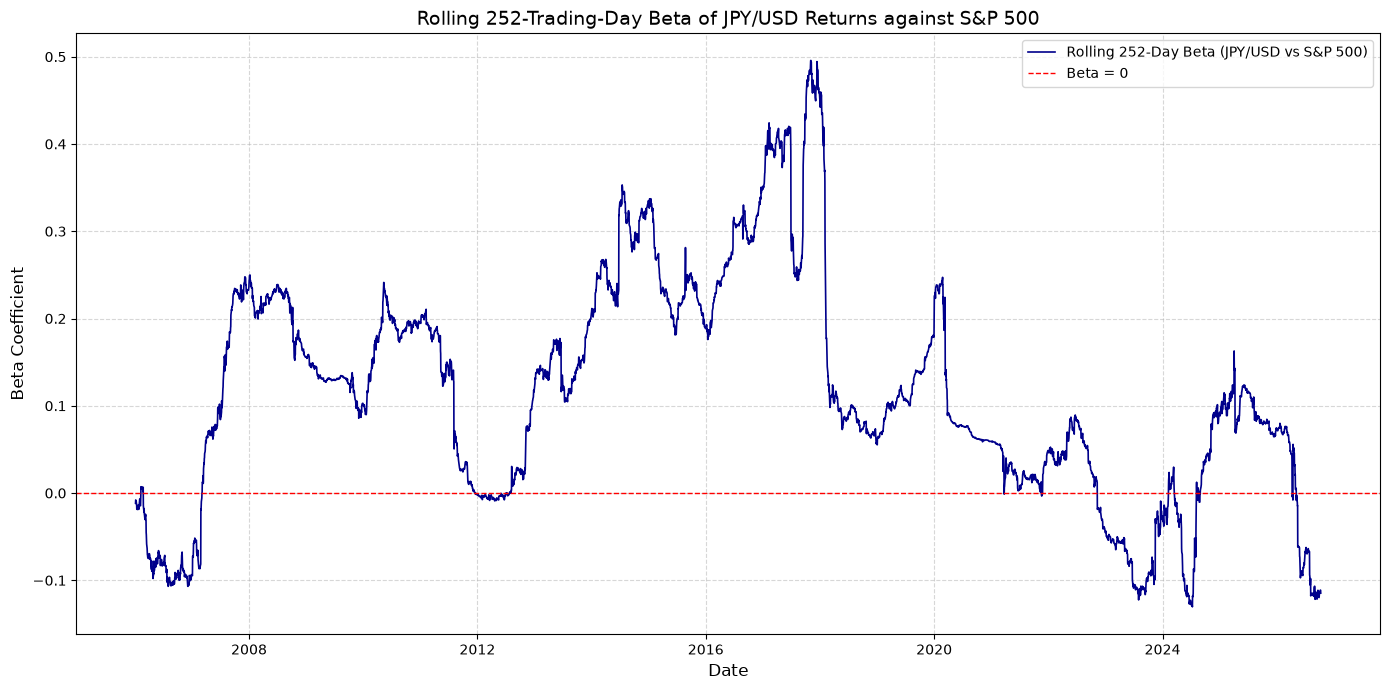

In [14]:
import matplotlib.pyplot as plt

# 4. Calculate statistical metrics (Beta) over a moving window of 252 trading days
rolling_window = 252

# Rolling covariance of JPY returns vs S&P 500 returns
rolling_covariance = merged_df['jpy_pct_return'].rolling(window=rolling_window).cov(merged_df['sp500_pct_return'])

# Rolling variance of S&P 500 returns
rolling_variance = merged_df['sp500_pct_return'].rolling(window=rolling_window).var()

# Compute Beta
merged_df['rolling_beta'] = rolling_covariance / rolling_variance

# 5. Plot the rolling Beta over the timeline
plt.figure(figsize=(14, 7))
plt.plot(merged_df.index, merged_df['rolling_beta'], label='Rolling 252-Day Beta (JPY/USD vs S&P 500)', color='darkblue', linewidth=1.2)
plt.axhline(0, color='red', linestyle='--', linewidth=1, label='Beta = 0')
plt.title('Rolling 252-Trading-Day Beta of JPY/USD Returns against S&P 500', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Beta Coefficient', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

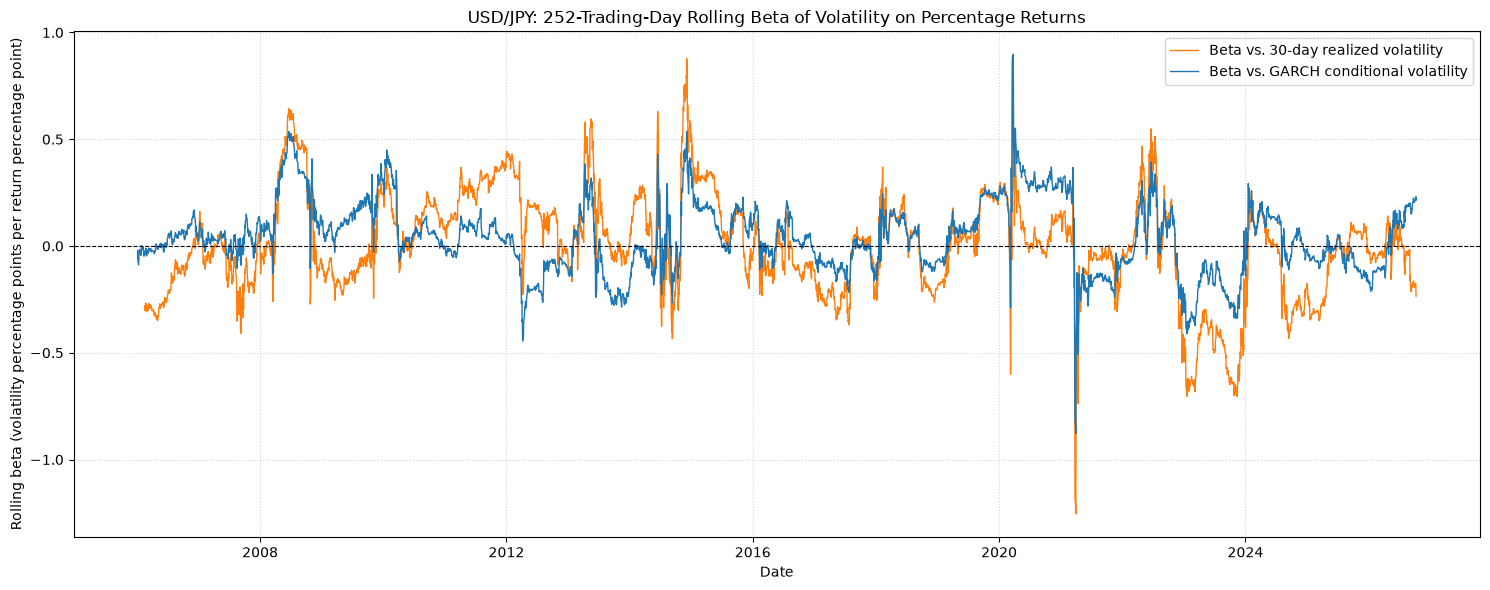

Rolling window: 252 trading days
Beta date range: 2006-01-04 to 2026-10-09


,Rolling beta vs. 30-day realized volatility,Rolling beta vs. GARCH volatility
observation_date,,
2026-10-05,-0.175107,0.217521
2026-10-06,-0.174747,0.217544
2026-10-07,-0.175248,0.217493
2026-10-08,-0.216867,0.230779
2026-10-09,-0.235123,0.215094


In [15]:
# Rolling 252-trading-day beta: USD/JPY percentage returns vs. volatility.
# Beta is the slope from volatility_t = alpha + beta * return_t + error_t.
from arch import arch_model
from IPython.display import display

rolling_fx = fx_df[['observation_date', 'DEXJPUS']].copy()
rolling_fx['observation_date'] = pd.to_datetime(rolling_fx['observation_date'], errors='coerce')
rolling_fx['DEXJPUS'] = pd.to_numeric(rolling_fx['DEXJPUS'], errors='coerce')
rolling_fx = rolling_fx.dropna().set_index('observation_date').sort_index()

# Daily USD/JPY percentage returns, expressed in percentage points.
rolling_returns_pct = rolling_fx['DEXJPUS'].pct_change(fill_method=None).dropna() * 100

# Compare returns with two volatility measures, both annualized in percent.
rolling_realized_vol = (
    rolling_returns_pct.rolling(window=30, min_periods=30).std() * np.sqrt(252)
)
rolling_garch_fit = arch_model(
    rolling_returns_pct, mean='Constant', vol='Garch', p=1, q=1, dist='normal'
).fit(disp='off')
rolling_garch_vol = rolling_garch_fit.conditional_volatility * np.sqrt(252)

# Rolling beta = rolling covariance(return, volatility) / rolling variance(return).
rolling_beta_window = 252
rolling_return_variance = rolling_returns_pct.rolling(
    window=rolling_beta_window, min_periods=rolling_beta_window
).var()
rolling_beta_realized = (
    rolling_returns_pct.rolling(window=rolling_beta_window, min_periods=rolling_beta_window)
    .cov(rolling_realized_vol)
    .div(rolling_return_variance)
)
rolling_beta_garch = (
    rolling_returns_pct.rolling(window=rolling_beta_window, min_periods=rolling_beta_window)
    .cov(rolling_garch_vol)
    .div(rolling_return_variance)
)

rolling_beta_results = pd.DataFrame({
    'Rolling beta vs. 30-day realized volatility': rolling_beta_realized,
    'Rolling beta vs. GARCH volatility': rolling_beta_garch,
}).dropna(how='all')
if rolling_beta_results.empty:
    raise ValueError('Not enough aligned USD/JPY observations to calculate a 252-day rolling beta.')

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(
    rolling_beta_results.index,
    rolling_beta_results['Rolling beta vs. 30-day realized volatility'],
    color='tab:orange', linewidth=1,
    label='Beta vs. 30-day realized volatility'
)
ax.plot(
    rolling_beta_results.index,
    rolling_beta_results['Rolling beta vs. GARCH volatility'],
    color='tab:blue', linewidth=1,
    label='Beta vs. GARCH conditional volatility'
)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('USD/JPY: 252-Trading-Day Rolling Beta of Volatility on Percentage Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Rolling beta (volatility percentage points per return percentage point)')
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend()
fig.tight_layout()
plt.show()

print(f'Rolling window: {rolling_beta_window} trading days')
print(f'Beta date range: {rolling_beta_results.index.min().date()} to {rolling_beta_results.index.max().date()}')
display(rolling_beta_results.tail())

Observations: 5,455 (2005-01-04 to 2026-10-09)


C:\Users\guosh\AppData\Local\Temp\ipykernel_25816\760878866.py:28: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p = adfuller(jpy_mrs_data['Returns'])[:2]
C:\Users\guosh\AppData\Local\Temp\ipykernel_25816\760878866.py:29: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_stat, kpss_p = kpss(jpy_mrs_data['Returns'], nla


--- Stationarity Tests ---
ADF  statistic: -53.5837 | p-value: 0.0000 -> stationary
KPSS statistic: 0.1913 | p-value: 0.1000 -> stationary
AR order 0: AIC = 9309.75
AR order 1: AIC = 9306.07
AR order 2: AIC = 9304.79
AR order 3: AIC = 9303.29
AR order 4: AIC = 9305.71
AR order 5: AIC = 9300.70

Best AR order (by AIC): 5
                         Markov Switching Model Results                         
Dep. Variable:                  Returns   No. Observations:                 5450
Model:             MarkovAutoregression   Log Likelihood               -4639.348
Date:                  Fri, 30 Oct 2026   AIC                           9300.696
Time:                          19:16:21   BIC                           9373.333
Sample:                               0   HQIC                          9326.044
                                 - 5450                                         
Covariance Type:                 approx                                         
                             

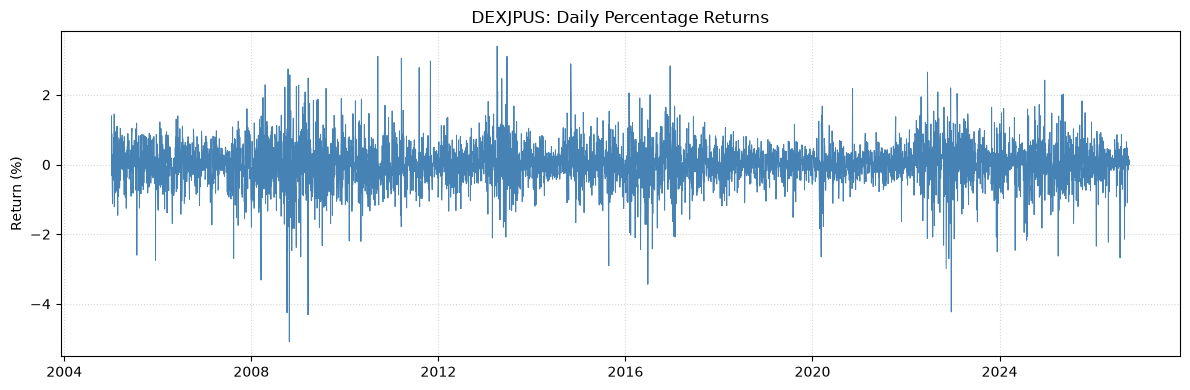

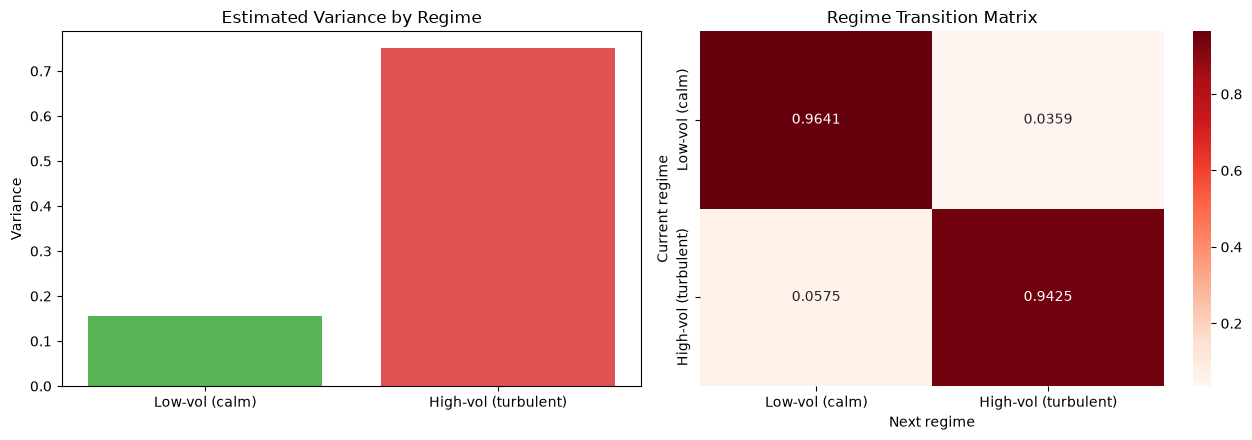

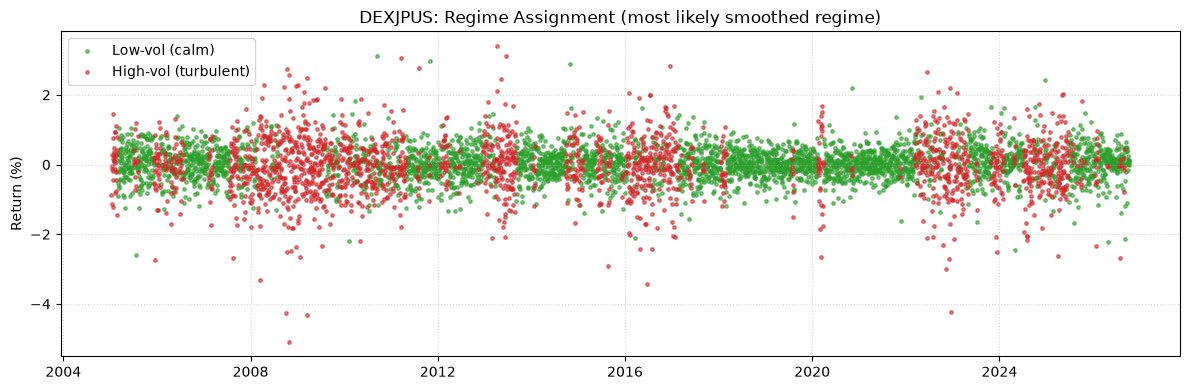

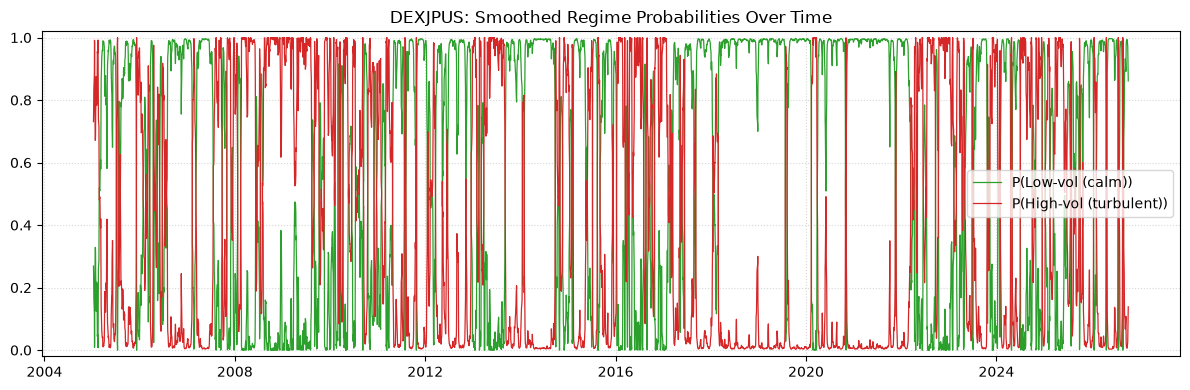

In [16]:
# Two-regime Markov Regime Switching model on USD/JPY daily % returns (DEXJPUS)
# Methodology follows Öztürk's MRS tutorial: stationarity tests -> AR order by AIC -> 2-regime
# model with switching variance -> diagnostics -> variance / transition / regime plots.

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
from statsmodels.tsa.regime_switching.markov_autoregression import MarkovAutoregression
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import normaltest

warnings.filterwarnings('ignore', category=UserWarning)   # silences statsmodels date-index / KPSS warnings

# ---------- 1. Daily percentage returns of DEXJPUS (same cleaning as the earlier cells) ----------
jpy_mrs_px = fx_df[['observation_date', 'DEXJPUS']].copy()
jpy_mrs_px['observation_date'] = pd.to_datetime(jpy_mrs_px['observation_date'], errors='coerce')
jpy_mrs_px['DEXJPUS'] = pd.to_numeric(jpy_mrs_px['DEXJPUS'], errors='coerce')
jpy_mrs_px = jpy_mrs_px.dropna().set_index('observation_date').sort_index()

jpy_mrs_data = pd.DataFrame({'Returns': jpy_mrs_px['DEXJPUS'].pct_change(fill_method=None) * 100}).dropna()
print(f"Observations: {len(jpy_mrs_data):,} ({jpy_mrs_data.index.min().date()} to {jpy_mrs_data.index.max().date()})")

# ---------- 2. Stationarity tests (ADF + KPSS) ----------
adf_stat, adf_p = adfuller(jpy_mrs_data['Returns'])[:2]
kpss_stat, kpss_p = kpss(jpy_mrs_data['Returns'], nlags='auto')[:2]
print("\n--- Stationarity Tests ---")
print(f"ADF  statistic: {adf_stat:.4f} | p-value: {adf_p:.4f} -> {'stationary' if adf_p < 0.05 else 'likely non-stationary'}")
print(f"KPSS statistic: {kpss_stat:.4f} | p-value: {kpss_p:.4f} -> {'likely non-stationary' if kpss_p < 0.05 else 'stationary'}")

# ---------- 3. Best AR order (0-5) by AIC, always with 2 regimes ----------
# Note: the tutorial passes `order` to MarkovRegression, but in statsmodels that argument is not an AR lag.
# Order 0 = MarkovRegression (regime-dependent mean + variance); order p > 0 = MarkovAutoregression (AR(p)).
def jpy_mrs_fit(order, **fit_kwargs):
    if order == 0:
        mod = MarkovRegression(jpy_mrs_data['Returns'], k_regimes=2, switching_variance=True)
    else:
        mod = MarkovAutoregression(jpy_mrs_data['Returns'], k_regimes=2, order=order,
                                   switching_ar=False, switching_variance=True)
    return mod.fit(**fit_kwargs)

jpy_mrs_max_order = 5
jpy_mrs_best_aic, jpy_mrs_best_order = np.inf, 0
for order in range(jpy_mrs_max_order + 1):
    try:
        trial = jpy_mrs_fit(order, disp=False)
        print(f"AR order {order}: AIC = {trial.aic:.2f}")
        if trial.aic < jpy_mrs_best_aic:
            jpy_mrs_best_aic, jpy_mrs_best_order = trial.aic, order
    except Exception as e:
        print(f"AR order {order}: failed ({type(e).__name__})")
print(f"\nBest AR order (by AIC): {jpy_mrs_best_order}")

# ---------- 4. Fit the final two-regime Markov switching model ----------
jpy_mrs_res = jpy_mrs_fit(jpy_mrs_best_order)
print(jpy_mrs_res.summary())

# Label regimes by estimated variance so "Calm" / "Turbulent" are unambiguous
jpy_mrs_var = pd.Series({i: jpy_mrs_res.params[f'sigma2[{i}]'] for i in range(2)})
calm, turb = jpy_mrs_var.idxmin(), jpy_mrs_var.idxmax()
jpy_mrs_names = {calm: 'Low-vol (calm)', turb: 'High-vol (turbulent)'}

# ---------- 5. Diagnostics ----------
print("\n--- Model Diagnostics ---")
try:
    jpy_mrs_resid = jpy_mrs_res.resid
except AttributeError:   # fallback: standardised residual from the smoothed-probability mixture (order 0 only)
    _p = jpy_mrs_res.smoothed_marginal_probabilities
    _mu = sum(_p[i] * jpy_mrs_res.params[f'const[{i}]'] for i in range(2))
    _sd = np.sqrt(sum(_p[i] * jpy_mrs_res.params[f'sigma2[{i}]'] for i in range(2)))
    jpy_mrs_resid = (jpy_mrs_data['Returns'].loc[_p.index] - _mu) / _sd
print("Ljung-Box (lag 10) on residuals:")
print(acorr_ljungbox(jpy_mrs_resid, lags=[10], return_df=True))
norm = normaltest(jpy_mrs_resid)
print(f"\nD'Agostino-Pearson normality: stat = {norm.statistic:.4f}, p = {norm.pvalue:.4f} -> "
      f"{'residuals not normal' if norm.pvalue < 0.05 else 'residuals look normal'}")

# ---------- 6. Key parameters ----------
print("\n--- Key Parameters ---")
print(f"AIC: {jpy_mrs_res.aic:.2f} | BIC: {jpy_mrs_res.bic:.2f} | Log-Likelihood: {jpy_mrs_res.llf:.2f}")
for i in (calm, turb):
    print(f"{jpy_mrs_names[i]}: variance = {jpy_mrs_var[i]:.4f}, daily vol = {np.sqrt(jpy_mrs_var[i]):.3f}%, "
          f"annualised vol = {np.sqrt(jpy_mrs_var[i] * 252):.1f}%, mean = {jpy_mrs_res.params[f'const[{i}]']:.4f}%")

# Transition matrix: statsmodels stores P(to i | from j) in [i, j]; transpose so rows = current, cols = next
jpy_mrs_P = np.asarray(jpy_mrs_res.regime_transition)
if jpy_mrs_P.ndim == 3:
    jpy_mrs_P = jpy_mrs_P[:, :, 0]
jpy_mrs_P = jpy_mrs_P.T
print("\nTransition matrix (rows = current regime, cols = next regime):")
print(pd.DataFrame(jpy_mrs_P, index=[jpy_mrs_names[i] for i in range(2)],
                   columns=[jpy_mrs_names[i] for i in range(2)]).round(4))
print("\nExpected regime durations (days):")
for i in (calm, turb):
    print(f"  {jpy_mrs_names[i]}: {1 / (1 - jpy_mrs_P[i, i]):.1f}")

# ---------- 7. Plots ----------
probs = jpy_mrs_res.smoothed_marginal_probabilities
jpy_mrs_regime = probs.idxmax(axis=1)
jpy_mrs_ret = jpy_mrs_data['Returns'].loc[probs.index]      # aligned (AR terms drop the first `order` obs)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(jpy_mrs_data.index, jpy_mrs_data['Returns'], color='steelblue', linewidth=0.7)
ax.set_title('DEXJPUS: Daily Percentage Returns')
ax.set_ylabel('Return (%)'); ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar([jpy_mrs_names[i] for i in (calm, turb)], [jpy_mrs_var[calm], jpy_mrs_var[turb]],
            color=['tab:green', 'tab:red'], alpha=0.8)
axes[0].set_title('Estimated Variance by Regime'); axes[0].set_ylabel('Variance')
sns.heatmap(jpy_mrs_P, annot=True, fmt='.4f', cmap='Reds', ax=axes[1],
            xticklabels=[jpy_mrs_names[i] for i in range(2)],
            yticklabels=[jpy_mrs_names[i] for i in range(2)])
axes[1].set_title('Regime Transition Matrix'); axes[1].set_xlabel('Next regime'); axes[1].set_ylabel('Current regime')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
for i, colour in ((calm, 'tab:green'), (turb, 'tab:red')):
    mask = jpy_mrs_regime == i
    ax.scatter(jpy_mrs_ret.index[mask], jpy_mrs_ret[mask], s=6, alpha=0.6, color=colour, label=jpy_mrs_names[i])
ax.set_title('DEXJPUS: Regime Assignment (most likely smoothed regime)')
ax.set_ylabel('Return (%)'); ax.legend(); ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
for i, colour in ((calm, 'tab:green'), (turb, 'tab:red')):
    ax.plot(probs[i], color=colour, linewidth=0.9, label=f'P({jpy_mrs_names[i]})')
ax.set_title('DEXJPUS: Smoothed Regime Probabilities Over Time')
ax.set_ylim(-0.02, 1.02); ax.legend(); ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout(); plt.show()
